# Output Verification

Prototype of the output screening in the verification plan (`docs/validation-plan.md`), developed on a few studies. Every section computes its metrics and plots them right away.

In [17]:
import os
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.stats import gmean, gstd
from matplotlib.ticker import ScalarFormatter
from babelbetes import data_store, drawing, tdd

%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.dpi'] = 150  # sharper inline display, savefig keeps dpi=300

STORE_PATH = os.path.join(os.getcwd(), '..', 'data', 'out')
STUDIES = ['Flair', 'PEDAP', 'T1DEXI']  # all except Loop: ['DCLP3', 'DCLP5', 'Flair', 'IOBP2', 'PEDAP', 'ReplaceBG', 'T1DEXI', 'T1DEXIP']
STREAMS = ['cgm', 'bolus', 'basal']
KEYS = ['study_name', 'patient_id']

RUN_ID = pd.Timestamp.now().strftime('%Y-%m-%d_%H%M%S')
SAVE_RUN = True  # False for test runs: nothing is written to docs/validation/runs, figures go to notebooks/figures
RUN_DIR = os.path.join(os.getcwd(), '..', 'validation', 'runs', RUN_ID)
FIGURE_DIR = os.path.join(RUN_DIR, 'figures') if SAVE_RUN else os.path.join(os.getcwd(), 'figures')
os.makedirs(FIGURE_DIR, exist_ok=True)

PALETTE = dict(zip(STUDIES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#4a3aa7', '#17a2b8', '#8c564b']))

MIN_TDD = 1.0  # U, days below are zero-dose days and not part of the TDD statistics
TOP_N = 1   # rows shown in the outlier tables; the cases are chosen in the Case Tracking notebook
candidates = []  # flagged patients of every check, exported in the section Export

In [ ]:
store = data_store.load(STORE_PATH, data_types=STREAMS, studies=STUDIES, categorical_keys=True)

## Hard Checks

Plan §4 A. The limits hold for every study: the reporting range of Abbott and Dexcom sensors, and the largest bolus and basal maxima across Omnipod, MiniMed and Tandem pumps. Every violation counts; the table lists the top `TOP_N` patients per study and check.

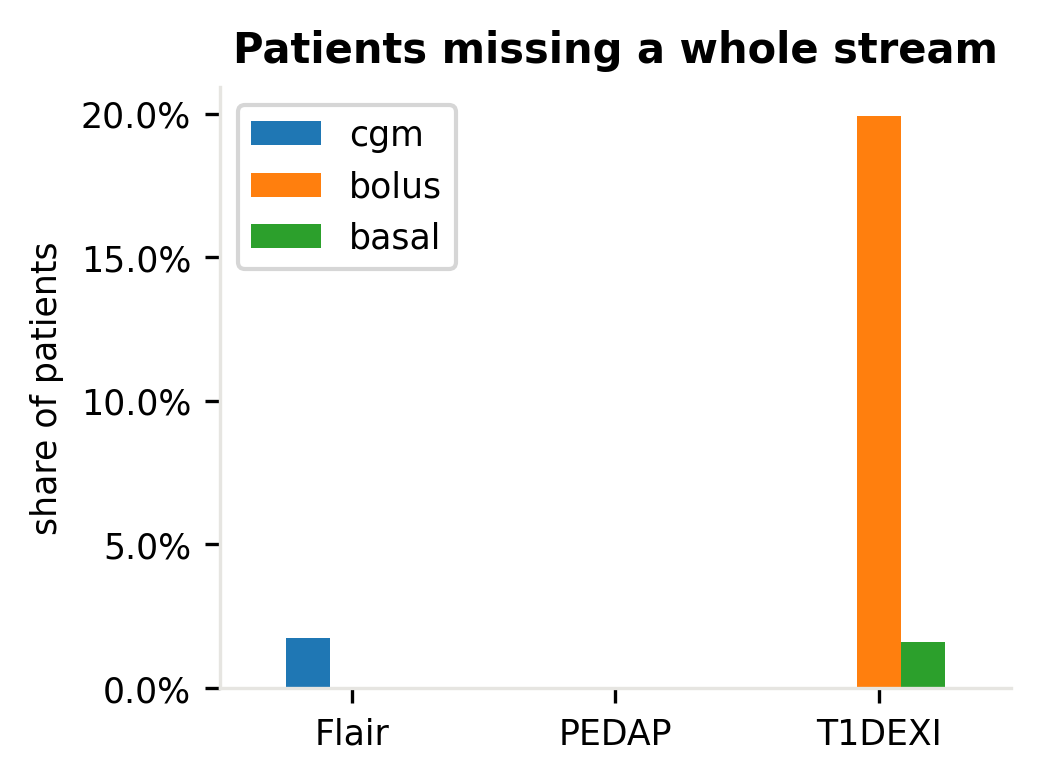

In [ ]:
# share of patients per study that miss a whole stream
df_streams = pd.DataFrame({s: store[s].groupby(KEYS, observed=True).size() for s in STREAMS})
df_missing_stream = df_streams.loc[df_streams.isna().any(axis=1)]

from matplotlib.ticker import PercentFormatter
f,ax = drawing.default_figure(1 + 0.8 * len(STUDIES), 2.6)
df_streams.isna().groupby('study_name', observed=True).mean().reindex(STUDIES).plot.bar(ax=ax, rot=0)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel=None, ylabel='share of patients', title='Patients missing a whole stream')
f.savefig(os.path.join(FIGURE_DIR, f"verification_missing_streams.png"), dpi=300, bbox_inches="tight")

# candidates: a missing stream counts against a fixed expectation, so rank across studies
candidates.append(df_missing_stream.isna().melt(ignore_index=False, var_name='check', value_name='flag').query('flag').reset_index()
                  .assign(check=lambda d: 'missing_' + d.check, value=1.0, scope='global'))

In [4]:
CGM_RANGE = (40, 400)  # mg/dL, reporting range of Abbott and Dexcom sensors
MAX_BOLUS = 35          # U, largest bolus maximum across Omnipod, MiniMed and Tandem
MAX_BASAL = 35          # U/h, largest basal maximum across Omnipod, MiniMed and Tandem

cgm, basal = store['cgm'], store['basal']
bolus = store['bolus'].sort_values(KEYS + ['datetime'])
# overlapping bolus: delivery still running when the next bolus starts
next_start = bolus.groupby(KEYS, observed=True).datetime.shift(-1)

# share of violating values per patient, one column per check
df_hard = pd.concat([
    cgm[KEYS].assign(cgm_below=cgm.cgm < CGM_RANGE[0], 
                     cgm_above=cgm.cgm > CGM_RANGE[1], 
                     cgm_missing=cgm.cgm.isna()),
    bolus[KEYS].assign(bolus_negative=bolus.bolus < 0, 
                       bolus_above=bolus.bolus > MAX_BOLUS,
                       bolus_overlap=bolus.datetime + bolus.delivery_duration > next_start),
    basal[KEYS].assign(basal_negative=basal.basal_rate < 0, 
                       basal_above=basal.basal_rate > MAX_BASAL),
]).groupby(KEYS, observed=True).mean()

# patients with at least one violation, per study and check
(df_hard > 0).groupby('study_name', observed=True).sum()

,cgm_below,cgm_above,cgm_missing,bolus_negative,bolus_above,bolus_overlap,basal_negative,basal_above
study_name,,,,,,,,
Flair,0,0,0,0,0,30,0,0
PEDAP,0,0,0,0,0,74,0,0
T1DEXI,308,131,0,0,0,105,0,25


In [5]:
# top patients per study and check, by share of violating values
df_violations = df_hard.melt(ignore_index=False, var_name='check', value_name='share').query('share > 0')

# candidates: share of violating values, fixed limits
candidates.append(df_violations.rename(columns={'share': 'value'}).reset_index().assign(scope='global'))

(df_violations.sort_values('share', ascending=False)
    .groupby(['study_name', 'check'], observed=True).head(TOP_N)
    .sort_values(['study_name', 'check', 'share'], ascending=[True, True, False]))

check     share
study_name patient_id                         
Flair      120         bolus_overlap  0.001646
PEDAP      32          bolus_overlap  0.190805
T1DEXI     306           basal_above   0.59322
           695         bolus_overlap  0.100775
           509             cgm_above   0.18638
           402             cgm_below  0.028459

## Population Checks

### Fit Functions

Robust bivariate lognormal fit per study (MCD). A patient is an outlier when its Mahalanobis distance from the study centre exceeds `THRESHOLD`.

In [6]:
from sklearn.covariance import EmpiricalCovariance, MinCovDet

THRESHOLD = 4.0  # Mahalanobis distance from the study centre that defines an outlier


def fit_population(df, log, robust):
    """Bivariate fit of the two columns of df (log values if log=True).

    robust=True estimates the fit from the tightest core of the points (Minimum
    Covariance Determinant), so extreme patients do not pull it; robust=False
    uses the plain mean and covariance.
    """
    X = np.log(df) if log else df
    estimator = MinCovDet(random_state=0) if robust else EmpiricalCovariance()
    return estimator.fit(X)


def find_outliers(df, fit, threshold, log):
    """Mahalanobis distance of every row of df to the fit, and whether it exceeds threshold.

    The distance counts standard deviations from the centre, corrected for the
    shape of the fit. sklearn returns squared distances, hence the sqrt.
    """
    X = np.log(df) if log else df
    distance = pd.Series(np.sqrt(fit.mahalanobis(X)), index=df.index, name='distance')
    return distance > threshold, distance


def plot_confidence_ellipses(fit, ax, log, n_stds=(1, 2, 3), n_points=200, **kwargs):
    """Draw concentric 'n standard deviations away' contours of the fit.

    If log=True, ellipses are built in log space and mapped back through exp(),
    so they appear curved (not true ellipses) in original units.
    """
    mean_x, mean_y = fit.location_
    std_x, std_y = np.sqrt(np.diag(fit.covariance_))
    r = fit.covariance_[0, 1] / (std_x * std_y)

    theta = np.linspace(0, 2 * np.pi, n_points)
    circle = np.vstack([np.sqrt(1 + r) * np.cos(theta), np.sqrt(1 - r) * np.sin(theta)])
    rot = np.array([[np.cos(np.pi/4), -np.sin(np.pi/4)],
                    [np.sin(np.pi/4),  np.cos(np.pi/4)]])
    circle = rot @ circle

    defaults = dict(alpha=0.6, color="black", linestyle="--")
    defaults.update(kwargs)

    lines = []
    label = defaults.pop('label',None)
    for n_std in n_stds:
        ex = circle[0] * std_x * n_std + mean_x
        ey = circle[1] * std_y * n_std + mean_y
        if log:
            ex, ey = np.exp(ex), np.exp(ey)
        if n_std==n_stds[-1]:
            defaults.update(label=label)
        line, = ax.plot(ex, ey, **defaults)
        lines.append(line)

    ax.relim()
    ax.autoscale_view()
    return lines

## TDD

Daily basal, bolus and total dose. Per patient: geometric mean and spread of the TDD over days with at least `MIN_TDD`.

In [7]:
basal = store['basal'].groupby(KEYS, observed=True).apply(tdd.calculate_daily_basal_dose, include_groups=False)
bolus = store['bolus'].groupby(KEYS, observed=True).apply(tdd.calculate_daily_bolus_dose, include_groups=False)
df_tdd = basal.join(bolus, how='outer')
df_tdd['tdd'] = df_tdd[['basal', 'bolus']].sum(axis=1, min_count=1)

### Zero TDDs

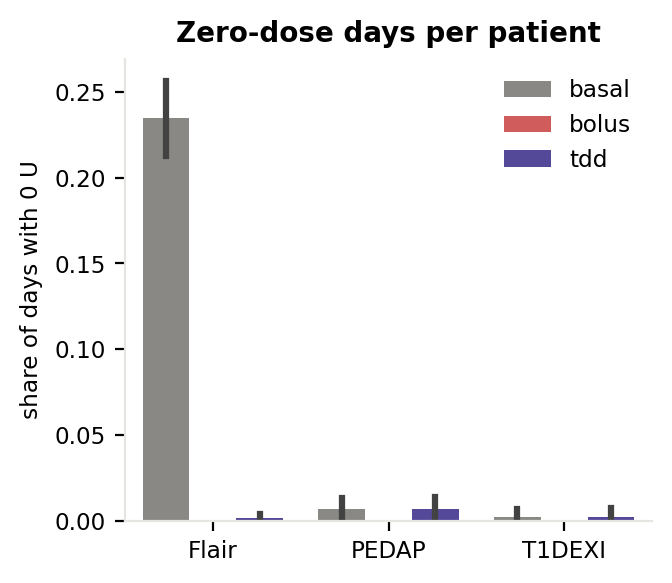

In [8]:
# share of days with no dose at all, per patient
df_zero = (df_tdd == 0).groupby(KEYS, observed=True).mean().melt(ignore_index=False, var_name='dose', value_name='share').reset_index()
palette = {'basal': drawing.colors['Basal'], 'bolus': drawing.colors['Bolus'], 'tdd': '#4a3aa7'}

f, ax = drawing.default_figure(1 + 0.8 * len(STUDIES), 3)
sns.barplot(df_zero, x='study_name', y='share', hue='dose', order=STUDIES, hue_order=list(palette), palette=palette,
            linewidth=0.8, ax=ax)
ax.set(xlabel=None, ylabel='share of days with 0 U', title='Zero-dose days per patient')
ax.legend(title=None, frameon=False)
f.savefig(os.path.join(FIGURE_DIR, f"verification_zero_dose_days.png"), dpi=300, bbox_inches="tight")

# candidates: share of zero-dose days, expected 0
candidates.append(df_zero.query('share > 0').rename(columns={'share': 'value'}).assign(check=lambda d: 'zero_' + d.dose, scope='global'))


### Bolus vs. Basal Ratio

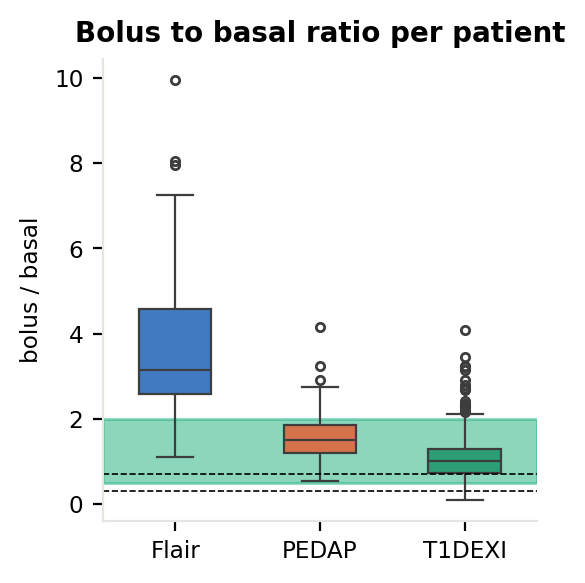

In [9]:
from importlib import reload
reload(drawing)
# bolus/basal ratio per patient: total bolus / total basal over days with both > 0
days = df_tdd[(df_tdd.basal > 0) & (df_tdd.bolus > 0)]
totals = days.groupby(KEYS, observed=True)[['basal', 'bolus']].sum()
df_ratio = (totals.bolus / totals.basal).rename('ratio').reset_index()

f, ax = drawing.default_figure(1 + 0.6 * len(STUDIES), 3)
sns.boxplot(df_ratio, x='study_name', y='ratio', hue='study_name', order=STUDIES, palette=PALETTE,
            flierprops=dict(marker='o', markersize=3), linewidth=0.8, ax=ax,
            width=0.5)
ax.axhline(0.3, color='black', linewidth=0.6, linestyle='--')  # bolus = basal
ax.axhline(0.7, color='black', linewidth=0.6, linestyle='--')  # bolus = basal
ax.axhspan(0.5,2,color=drawing.GREEN,alpha=0.5)
ax.set(xlabel=None, ylabel='bolus / basal', title='Bolus to basal ratio per patient')
ax.yaxis.set_major_formatter('{x:g}')
f.savefig(os.path.join(FIGURE_DIR, f"verification_bolus_basal_ratio.png"), dpi=300, bbox_inches="tight")

RATIO_RANGE = (0.5, 2)  # physiological bolus/basal range, the same for every study

# candidates: factor by which the ratio lies outside RATIO_RANGE
candidates.append(df_ratio.assign(value=np.maximum(RATIO_RANGE[0] / df_ratio.ratio, df_ratio.ratio / RATIO_RANGE[1]))
                  .query('value > 1').assign(check='bolus_basal_ratio', scope='global'))


### Bolus vs. Basal (per day) (just visual inspection)

study_name
Flair      99
PEDAP     395
T1DEXI     59
Name: outlier days, dtype: int64

basal  bolus   distance
study_name patient_id date                                  
PEDAP      44         2021-01-10  0.012500   3.60  13.233141
           14         2021-02-10  0.016694   2.02  12.073225
T1DEXI     956        2020-03-21  0.131357   2.30  10.913853

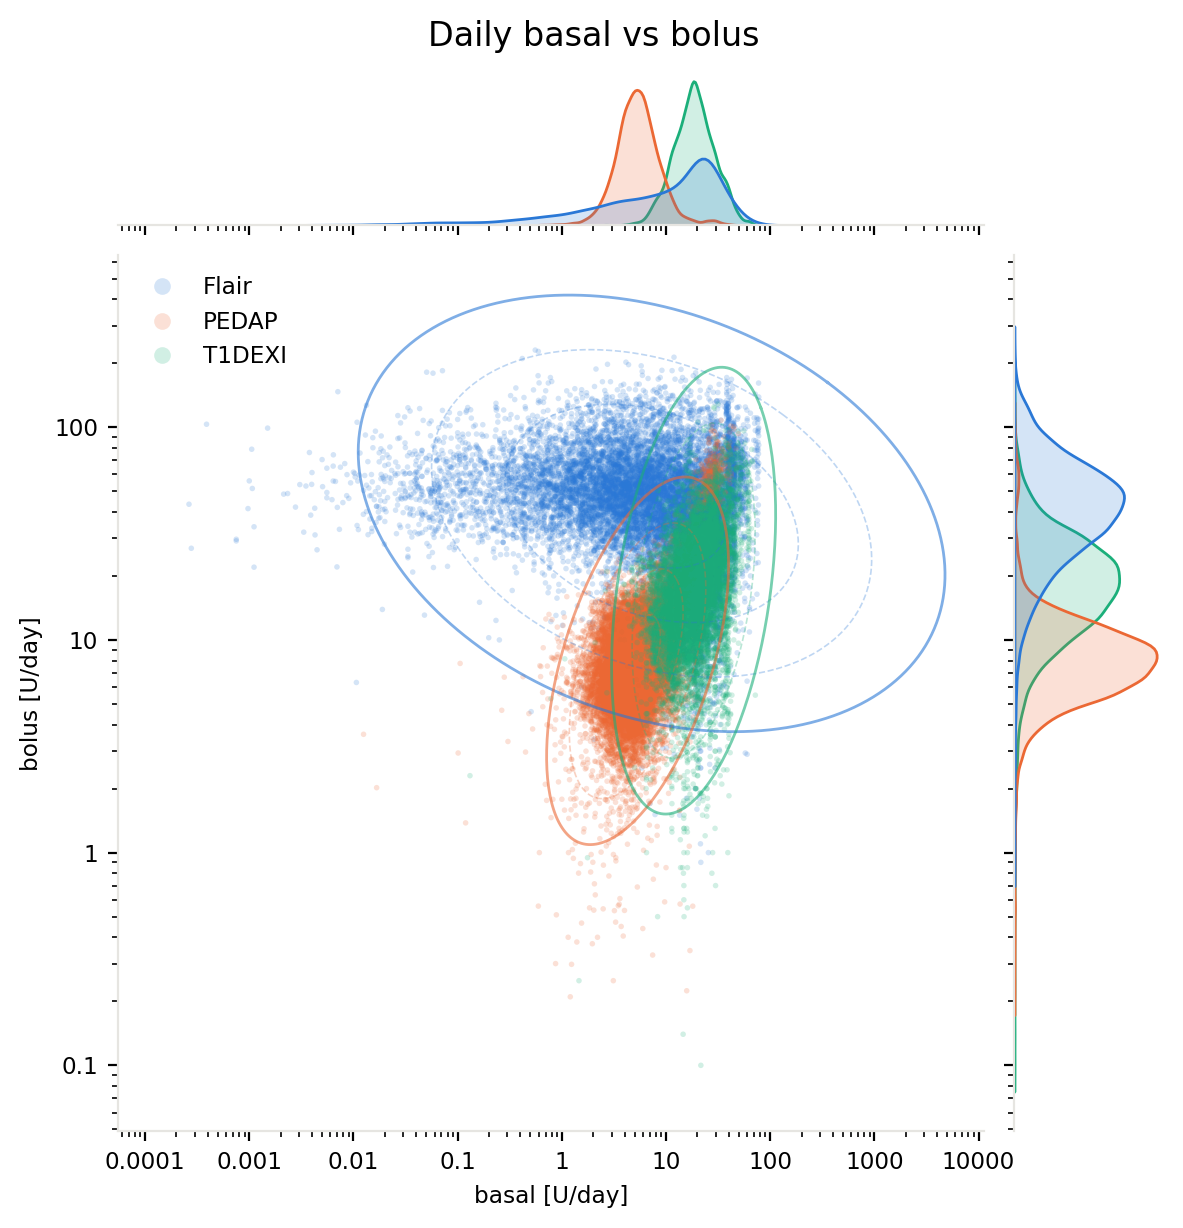

In [ ]:
# daily doses, days with both basal and bolus > 0
df_daily = df_tdd[['basal', 'bolus']].dropna()
df_daily = df_daily[(df_daily.basal > 0) & (df_daily.bolus > 0)]

g = sns.JointGrid(df_daily.reset_index(), x='basal', y='bolus', hue='study_name', hue_order=STUDIES, palette=PALETTE, height=6)
outliers = []
for study, df in df_daily.groupby('study_name', observed=True):
    fit = fit_population(df, log=True, robust=False)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    outliers.append(df[outlier].assign(distance=distance[outlier]))
    # contour first: it resets the axis limits to itself, the scatter afterwards extends them again
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[1, 2, 3], color=PALETTE[study], linestyle='--', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[THRESHOLD], color=PALETTE[study], linestyle='-', linewidth=1)
g.plot_joint(sns.scatterplot, s=4, alpha=0.2, edgecolor='none')
g.plot_marginals(sns.kdeplot, log_scale=True, common_norm=False, fill=True, alpha=0.2)

g.ax_joint.set(xlabel='basal [U/day]', ylabel='bolus [U/day]')
for axis in [g.ax_joint.xaxis, g.ax_joint.yaxis]:
    axis.set_major_formatter('{x:g}')
g.ax_marg_x.tick_params(which='both', labelbottom=False)
g.ax_marg_y.tick_params(which='both', labelleft=False)
g.ax_joint.legend(title=None, frameon=False, markerscale=3)
g.figure.suptitle('Daily basal vs bolus', y=1.02)
g.savefig(os.path.join(FIGURE_DIR, f"verification_daily_basal_vs_bolus.png"), dpi=300, bbox_inches="tight")

df_outliers = pd.concat(outliers).sort_values('distance', ascending=False)
display(df_outliers.groupby('study_name', observed=True).size().rename('outlier days'))
df_outliers[~df_outliers.index.droplevel('date').duplicated()].head(3)  # most extreme day of each subject

### Mean vs. STD

'Study Medians:'

,mu,sigma
study_name,,
Flair,53.578112,1.236999
PEDAP,13.290725,1.261982
T1DEXI,34.038043,1.167909


'Outliers:'

,,mu,sigma,distance
study_name,patient_id,,,
T1DEXI,1327,5.51168,7.331023,44.128052


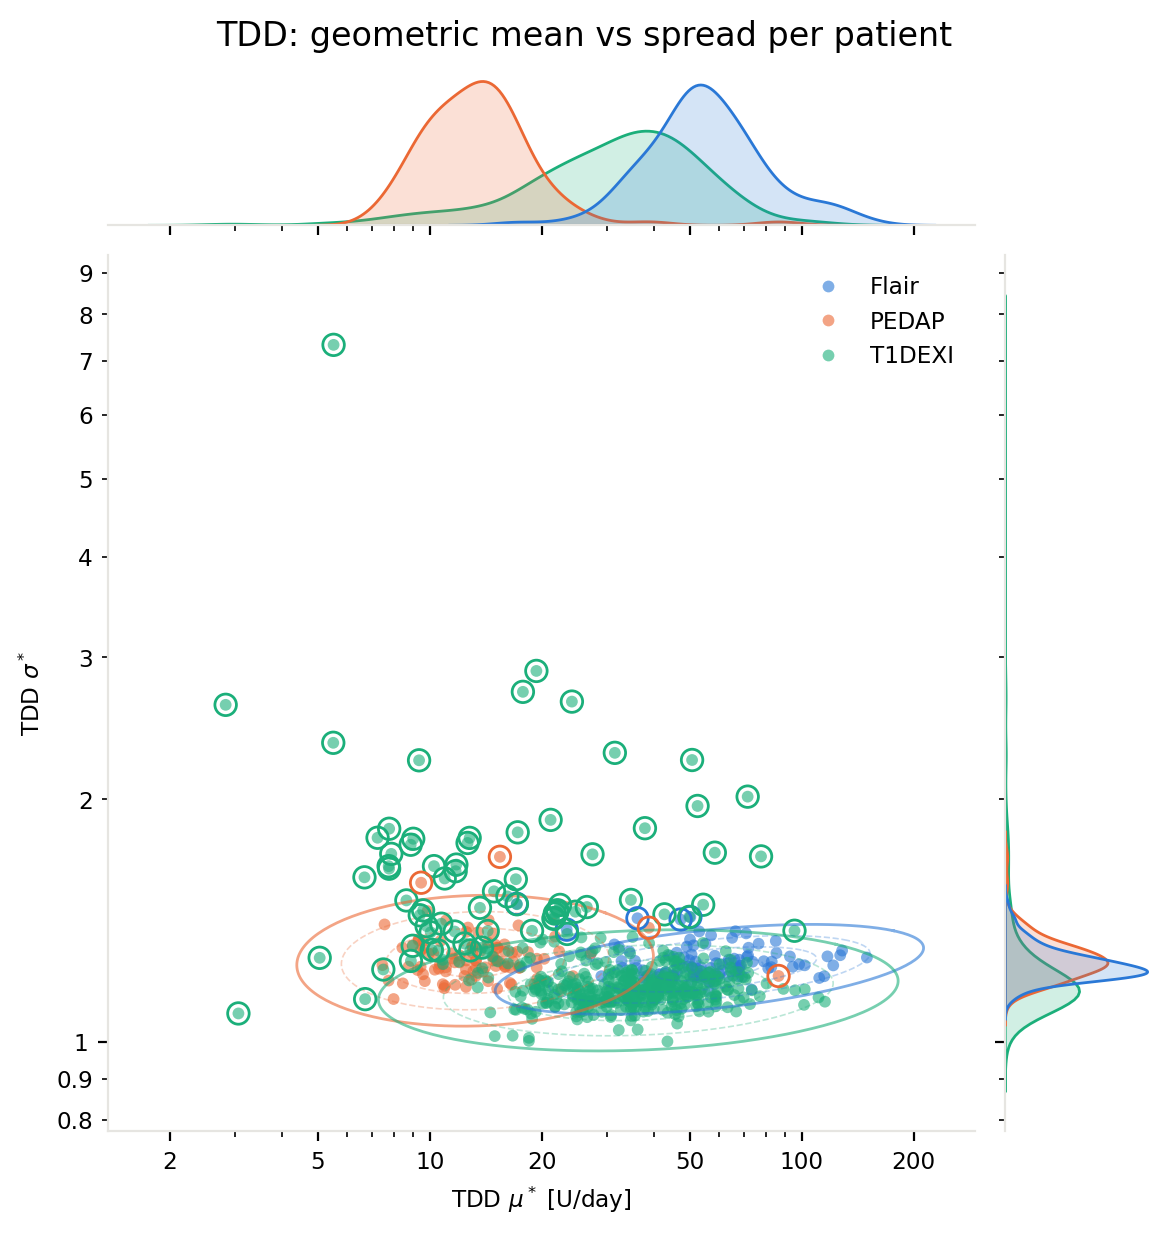

In [10]:
# mean vs std
valid = df_tdd[df_tdd.tdd >= MIN_TDD].groupby(KEYS, observed=True).tdd
df_tdd_patient = pd.DataFrame({
    'mu': valid.agg(gmean),
    'sigma': valid.agg(lambda x: gstd(x) if len(x) > 1 else np.nan),  # undefined for a single day
})
display("Study Medians:")
display(df_tdd_patient.groupby('study_name', observed=True).median())

g = sns.JointGrid(df_tdd_patient.reset_index(), x='mu', y='sigma', hue='study_name', hue_order=STUDIES, palette=PALETTE, height=6)
outliers = []
for study, df in df_tdd_patient[['mu', 'sigma']].dropna().groupby('study_name', observed=True):
    fit = fit_population(df, log=True, robust=True)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    outliers.append(df[outlier].assign(distance=distance[outlier]))
    # contour first: it resets the axis limits to itself, the scatter afterwards extends them again
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[1, 2, 3], color=PALETTE[study], linestyle='--', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[THRESHOLD], color=PALETTE[study], linestyle='-', linewidth=1)
g.plot_joint(sns.scatterplot, s=18, alpha=0.6, edgecolor='none')
g.plot_marginals(sns.kdeplot, log_scale=True, common_norm=False, fill=True, alpha=0.2)

# ring the outliers in their study color
df_tdd_outliers = pd.concat(outliers).sort_values('distance', ascending=False)
g.ax_joint.scatter(df_tdd_outliers.mu, df_tdd_outliers.sigma, s=60, facecolors='none', linewidths=1, zorder=5,
                   edgecolors=[PALETTE[s] for s in df_tdd_outliers.index.get_level_values('study_name')])
g.ax_joint.set(xlabel=r'TDD $\mu^*$ [U/day]', ylabel=r'TDD $\sigma^*$')
g.ax_joint.set_xticks([2, 5, 10, 20, 50, 100, 200], minor=False)
g.ax_joint.xaxis.set_major_formatter('{x:g}')
g.ax_joint.xaxis.set_minor_formatter('')
g.ax_joint.yaxis.set_major_formatter('{x:g}')
g.ax_joint.yaxis.set_minor_formatter('{x:g}')
g.ax_marg_x.tick_params(which='both', labelbottom=False)
g.ax_marg_y.tick_params(which='both', labelleft=False)
g.ax_joint.legend(title=None, frameon=False)
g.figure.suptitle('TDD: geometric mean vs spread per patient', y=1.02)
g.savefig(os.path.join(FIGURE_DIR, f"verification_tdd_mean_vs_spread.png"), dpi=300, bbox_inches="tight")

# candidates: distance from the study's own fit, so rank per study
candidates.append(df_tdd_outliers.distance.rename('value').reset_index().assign(check='tdd_mu_sigma', scope='study'))

display("Outliers:")
df_tdd_outliers.head(TOP_N)

### CGM

A gap is irregular when it is not a multiple of 5 min (±5 s). Runs of irregular gaps up to 30 min form a section; longer gaps are dropouts or sensor changes. A section of at least 12 gaps that averages 2.5 min per gap is two interleaved sensors. An hour jump is a gap of exactly n hours plus the patient's median gap (±1 s). Rate of change uses gaps up to 15 min.

irregular_hours  hour_jumps    cgm_mean  rate_of_change
study_name patient_id                                                         
T1DEXI     1120             619.748056           0  136.127198        1.894311
           484              517.050000           0  129.429916        0.889144
           897              467.452778           1  106.842656        0.833688
           1509             420.303333           0  127.060010        5.133350
           558              216.618333           0  220.239263        1.085559

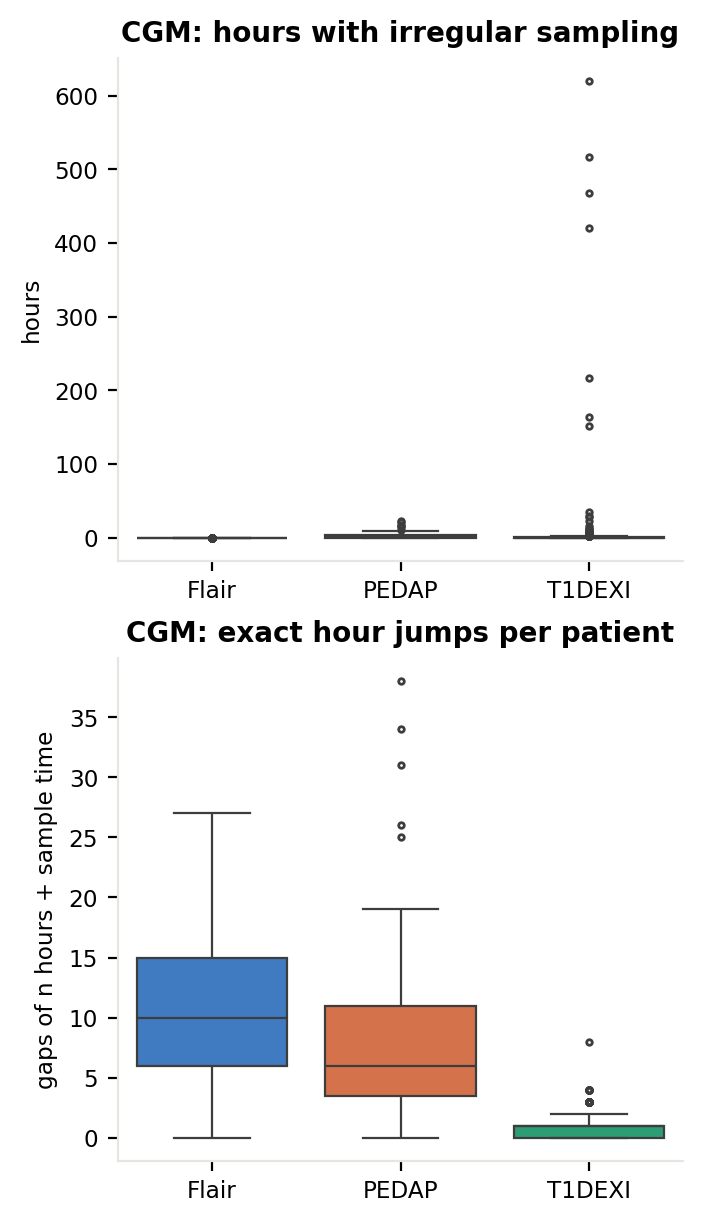

In [12]:
# gap to the previous reading of the same patient [s]
df_gaps = store['cgm'].sort_values(KEYS + ['datetime'])
patient = df_gaps.groupby(KEYS, observed=True)
df_gaps['gap'] = patient.datetime.diff().dt.total_seconds()

# irregular: not a multiple of 5 min (±10 s); gaps above 30 min are dropouts, not a wrong rate
rest = df_gaps.gap % 300
irregular = (rest > 10) & (rest < 290) & (df_gaps.gap <= 1800)

# sensor change: an irregular gap longer than 5 min followed by regular sampling (likely a sensor change)
phase_shift = irregular & (df_gaps.gap > 305) & ~irregular.shift(-1, fill_value=False)

df_gaps['irregular_seconds'] = df_gaps.gap.where(irregular & ~phase_shift, 0)

# hour jump: gap of exactly n hours plus the patient's usual gap (±1 s)
rest = (df_gaps.gap - patient.gap.transform('median')) % 3600
df_gaps['hour_jump'] = (df_gaps.gap > 3600) & ((rest <= 10) | (rest >= 3590))

# rate of change [mg/dL/min], only across gaps up to 15 min
df_gaps['roc'] = (patient.cgm.diff().abs() / (df_gaps.gap / 60)).where(df_gaps.gap <= 900)

# metrics per patient
patient = df_gaps.groupby(KEYS, observed=True)
df_cgm_patient = pd.DataFrame({
    'irregular_hours': patient.irregular_seconds.sum() / 3600,
    'hour_jumps': patient.hour_jump.sum(),
    'cgm_mean': patient.cgm.mean(),
    'rate_of_change': patient.roc.mean(),
})
df_cgm_patient.groupby('study_name', observed=True).median()

f, AX = plt.subplots(2, 1, figsize=(1 + 0.8 * len(STUDIES), 6), layout='constrained')
for ax, (column, ylabel, title) in zip(AX, [('irregular_hours', 'hours', 'CGM: hours with irregular sampling'),
                                           ('hour_jumps', 'gaps of n hours + sample time', 'CGM: exact hour jumps per patient')]):
    sns.boxplot(df_cgm_patient.reset_index(), x='study_name', y=column, hue='study_name', order=STUDIES, hue_order=STUDIES,
                palette=PALETTE, dodge=False, linewidth=0.8, flierprops=dict(marker='.', markersize=4), ax=ax)
    ax.set(xlabel=None, ylabel=ylabel, title=title)

f.savefig(os.path.join(FIGURE_DIR, f"verification_cgm_irregular_hours_and_jumps.png"), dpi=300, bbox_inches="tight")

# candidates: irregular sampling and hour jumps are expected to be 0
candidates.append(df_cgm_patient.irregular_hours.rename('value').reset_index().query('value > 0').assign(check='cgm_irregular_hours', scope='global'))
candidates.append(df_cgm_patient.hour_jumps.rename('value').reset_index().query('value > 0').assign(check='cgm_hour_jumps', scope='global'))

df_cgm_patient.sort_values('irregular_hours', ascending=False).head(5)


#### CGM vs ROC

,,cgm_mean,rate_of_change,distance
study_name,patient_id,,,
PEDAP,29,149.728906,8.574287,19.237047


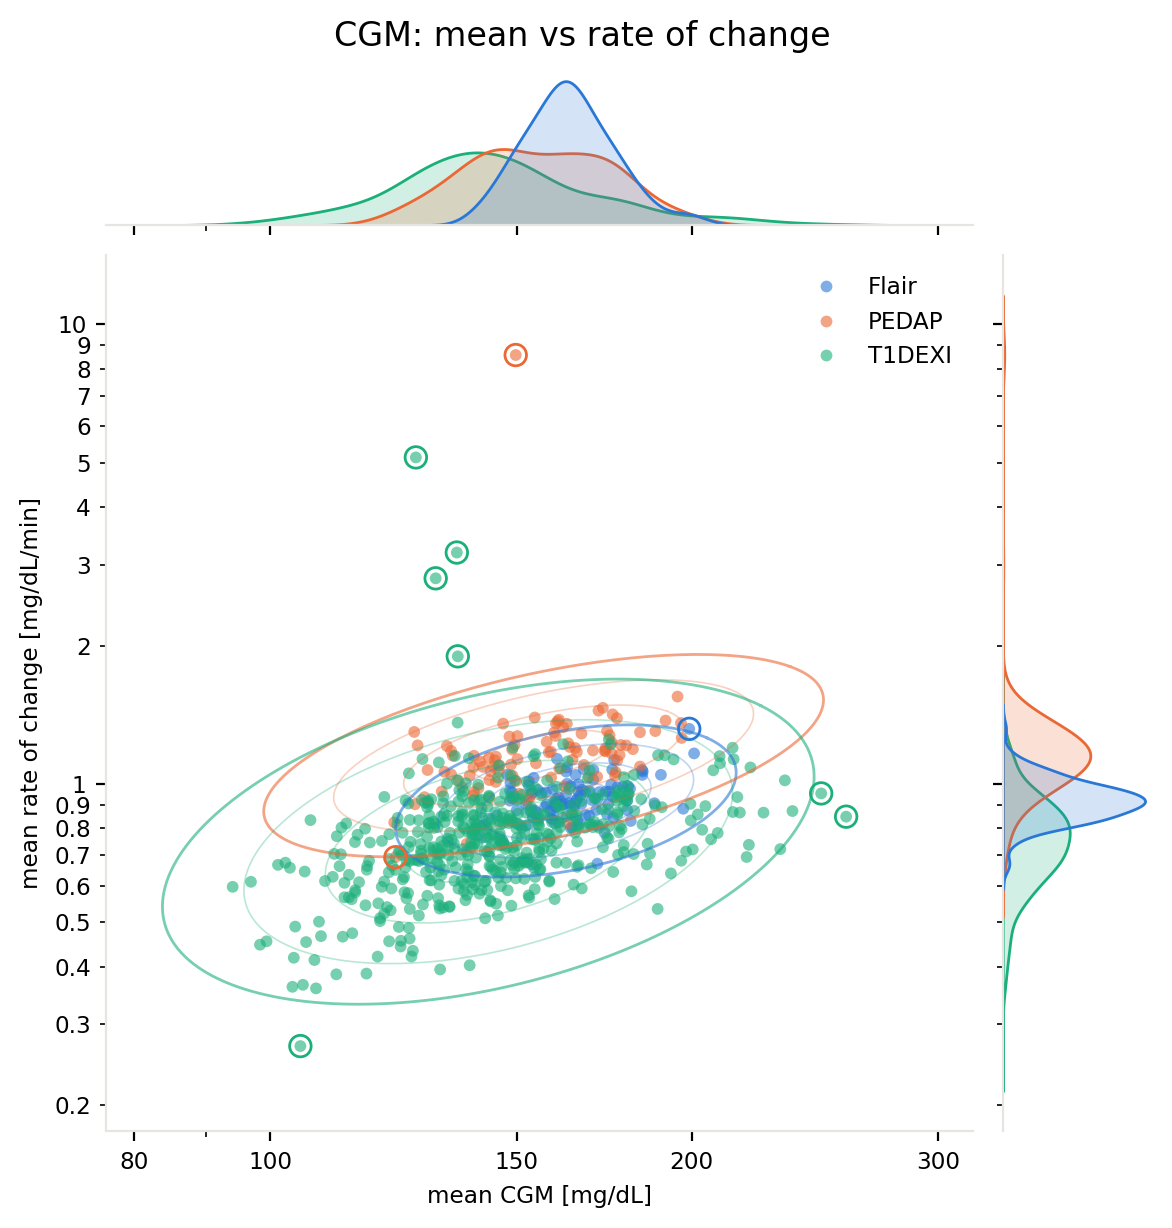

In [13]:
g = sns.JointGrid(df_cgm_patient.reset_index(), x='cgm_mean', y='rate_of_change', hue='study_name', hue_order=STUDIES, palette=PALETTE, height=6)
outliers = []
for study, df in df_cgm_patient[['cgm_mean', 'rate_of_change']].dropna().groupby('study_name', observed=True):
    fit = fit_population(df, log=True, robust=True)
    outlier, distance = find_outliers(df, fit, THRESHOLD, log=True)
    outliers.append(df[outlier].assign(distance=distance[outlier]))
    # contour first: it resets the axis limits to itself, the scatter afterwards extends them again
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[1, 2, 3], color=PALETTE[study], linestyle='-', linewidth=0.6, alpha=0.3)
    plot_confidence_ellipses(fit, g.ax_joint, log=True, n_stds=[THRESHOLD], color=PALETTE[study], linestyle='-', linewidth=1)
g.plot_joint(sns.scatterplot, s=18, alpha=0.6, edgecolor='none')
g.plot_marginals(sns.kdeplot, log_scale=True, common_norm=False, fill=True, alpha=0.2)

# ring the outliers in their study color
df_cgm_outliers = pd.concat(outliers).sort_values('distance', ascending=False)
g.ax_joint.scatter(df_cgm_outliers.cgm_mean, df_cgm_outliers.rate_of_change, s=60, facecolors='none', linewidths=1, zorder=5,
                   edgecolors=[PALETTE[s] for s in df_cgm_outliers.index.get_level_values('study_name')])
g.ax_joint.set(xlabel='mean CGM [mg/dL]', ylabel='mean rate of change [mg/dL/min]')
g.ax_joint.set_xticks([80, 100, 150, 200, 300], minor=False)
g.ax_joint.xaxis.set_major_formatter('{x:g}')
g.ax_joint.xaxis.set_minor_formatter('')
g.ax_joint.yaxis.set_major_formatter('{x:g}')
g.ax_joint.yaxis.set_minor_formatter('{x:g}')
g.ax_marg_x.tick_params(which='both', labelbottom=False)
g.ax_marg_y.tick_params(which='both', labelleft=False)
g.ax_joint.legend(title=None, frameon=False)
g.figure.suptitle('CGM: mean vs rate of change', y=1.02)
g.savefig(os.path.join(FIGURE_DIR, f"verification_cgm_mean_vs_roc.png"), dpi=300, bbox_inches="tight")

# candidates: distance from the study's own fit
candidates.append(df_cgm_outliers.distance.rename('value').reset_index().assign(check='cgm_mean_vs_roc', scope='study'))

df_cgm_outliers.head(TOP_N)

## Data Coverage

**Data coverage**: Share of days with *any data* between a patient's first and last day.   
**Data completeness**: Share of those days that have *all streams*.

,,total_days,complete_days,total_vs_median,completeness_ratio,distance
study_name,patient_id,,,,,
PEDAP,75,4,2,0.015504,0.5,1.104189


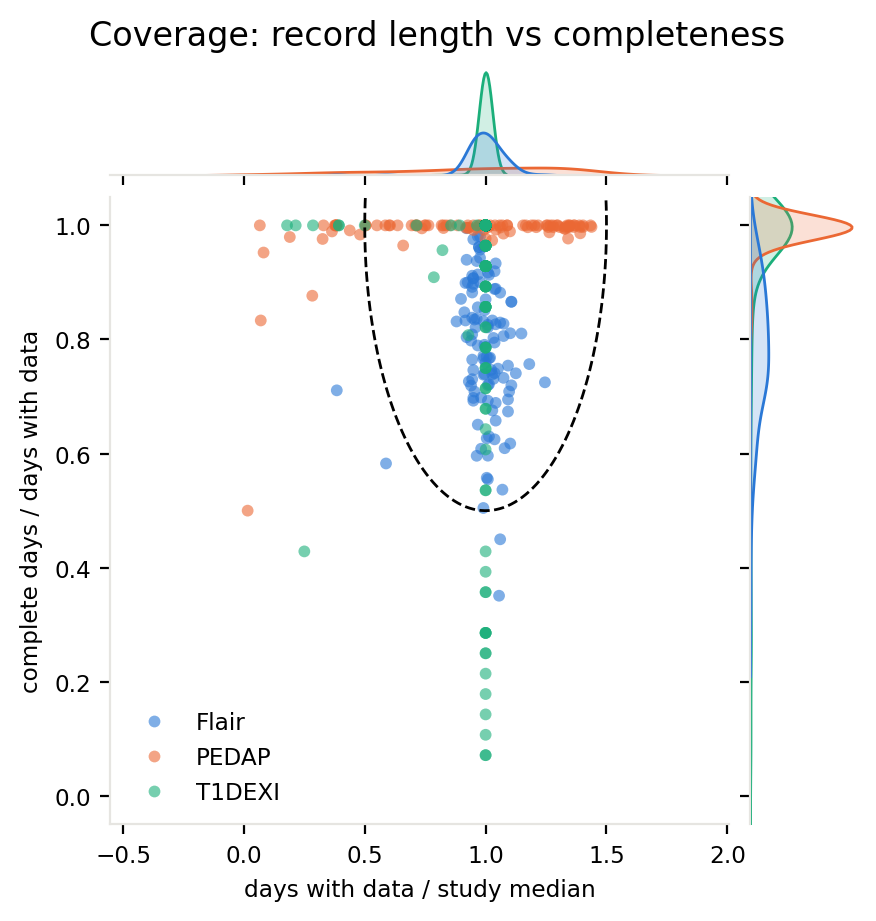

In [14]:
# count streams with data per patient and day
df_days = pd.concat([store[s][KEYS].assign(date=store[s].datetime.dt.normalize()).drop_duplicates() for s in STREAMS])
df_streams_per_day = df_days.groupby(KEYS + ['date'], observed=True).size().rename('streams').reset_index()

df_coverage = (df_streams_per_day.groupby(KEYS, observed=True)
    .agg(total_days=('date', 'size'), 
         complete_days=('streams', lambda s: (s >= len(STREAMS)).sum())))

#exclude patients without any data
df_coverage = df_coverage[~df_coverage.index.isin(df_missing_stream.index)]

#calcualte metrics
df_coverage['total_vs_median'] = df_coverage.total_days / df_coverage.groupby('study_name', observed=True).total_days.transform('median')
df_coverage['completeness_ratio'] = df_coverage.complete_days / df_coverage.total_days
df_coverage['distance'] = np.hypot(df_coverage.total_vs_median - 1, df_coverage.completeness_ratio - 1)

COVERAGE_LIMIT = 0.5  # distance from (1, 1) worth inspecting

# plot record length vs completeness with the limit circle
g = sns.jointplot(df_coverage.reset_index(), x='total_vs_median', y='completeness_ratio', hue='study_name', hue_order=STUDIES, palette=PALETTE,
                  height=4.5, 
                  joint_kws=dict(s=18, alpha=0.6, edgecolor='none'), marginal_kws=dict(common_norm=False, fill=True, alpha=0.2))
theta = np.linspace(0, 2 * np.pi, 200)
g.ax_joint.plot(1 + COVERAGE_LIMIT * np.cos(theta), 1 + COVERAGE_LIMIT * np.sin(theta), color='black', linewidth=1, linestyle='--')
g.ax_joint.set(xlabel='days with data / study median', ylabel='complete days / days with data', ylim=(-0.05, 1.05))
g.ax_joint.legend(title=None, frameon=False)
g.figure.suptitle('Coverage: record length vs completeness', y=1.02)
g.savefig(os.path.join(FIGURE_DIR, f"verification_coverage.png"), dpi=300, bbox_inches="tight")

# candidates: distance from the study median
candidates.append(df_coverage.query('distance > @COVERAGE_LIMIT').distance.rename('value').reset_index().assign(check='coverage', scope='study'))

# most extreme patients per study outside the limit
(df_coverage[df_coverage.distance > COVERAGE_LIMIT]
    .sort_values('distance', ascending=False)
    #.groupby('study_name', observed=True)
    .head(TOP_N))#.reset_index().sort_values(['study_name','distance'])


## Export

Writes this run to `docs/validation/runs/<RUN_ID>/`; the cases are chosen and tracked in `2026-11-12 - Case Tracking.ipynb`.

- `candidates.csv`: every flagged patient, one row per study, patient and check. `scope = global` checks compare against a fixed expectation, `scope = study` checks against the study's own distribution.
- `run.json`: code state of this notebook (metrics) and of the extraction (data, from `data/out/manifest.json`), the limits and the number of patients per study.
- `figures/`: all figures of this run.

In [15]:
CASE_KEYS = ['study_name', 'patient_id', 'check']

# every flagged patient of every check
df_cand = (pd.concat(candidates).astype({'study_name': str, 'patient_id': str})
           .drop_duplicates(CASE_KEYS)[CASE_KEYS + ['scope', 'value']].reset_index(drop=True))

# share of flagged patients per check and study
n_patients = pd.concat([store[s][KEYS] for s in STREAMS]).drop_duplicates().groupby('study_name', observed=True).size()
n_patients.index = n_patients.index.astype(str)
df_cand.groupby(['check', 'study_name']).size().unstack().div(n_patients).round(3)

study_name,Flair,PEDAP,T1DEXI
check,,,
basal_above,NaN,NaN,0.050
bolus_basal_ratio,0.870,0.192,0.115
bolus_overlap,0.261,0.747,0.211
cgm_above,NaN,NaN,0.264
cgm_below,NaN,NaN,0.620
cgm_hour_jumps,0.974,0.970,0.545
cgm_irregular_hours,0.209,0.909,0.634
cgm_mean_vs_roc,0.009,0.020,0.014
coverage,0.035,0.162,0.044


In [16]:
import json
import subprocess

# code state of the metrics (this notebook) and of the data (extraction manifest), limits and patient counts
git = lambda *args: subprocess.run(['git', *args], capture_output=True, text=True).stdout.strip()
manifest_path = os.path.join(STORE_PATH, 'manifest.json')
manifest = json.load(open(manifest_path)) if os.path.exists(manifest_path) else {}
run = dict(
    run=RUN_ID,
    notebook_commit=git('rev-parse', '--short', 'HEAD'),
    notebook_dirty=bool(git('status', '--porcelain', '--', '.')),
    studies=STUDIES,
    n_patients={study: int(n) for study, n in n_patients.items()},
    data={key: entry for key, entry in manifest.items() if key.split('/')[0] in STUDIES and key.split('/')[1] in STREAMS},
    limits=dict(THRESHOLD=THRESHOLD, MIN_TDD=MIN_TDD, CGM_RANGE=CGM_RANGE, MAX_BOLUS=MAX_BOLUS, MAX_BASAL=MAX_BASAL,
                RATIO_RANGE=RATIO_RANGE, COVERAGE_LIMIT=COVERAGE_LIMIT),
)

if SAVE_RUN:
    df_cand.to_csv(os.path.join(RUN_DIR, 'candidates.csv'), index=False)
    with open(os.path.join(RUN_DIR, 'run.json'), 'w') as f:
        json.dump(run, f, indent=2)
    print(f"Saved run {RUN_ID}: {len(df_cand)} candidates, {len(os.listdir(FIGURE_DIR))} figures")
else:
    print("Test run, nothing saved")

Saved run 2026-11-12_143344: 2179 candidates, 8 figures
